# Лабораторная работа №3
## Подготовка обучающей и тестовой выборки, кросс-валидация и подбор гиперпараметров на примере метода ближайших соседей

Источник: [UCI Wine](https://archive.ics.uci.edu/dataset/109/winedataset).
Aeberhard, S. & Forina, M.; DOI: 10.24432/C5PC7J; CC BY 4.0.
178 объектов, 13 числовых признаков, 3 класса.

## Библиотеки и настройки

In [1]:
from pathlib import Path
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    ConfusionMatrixDisplay, f1_score, precision_score, recall_score,
)
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV, RepeatedStratifiedKFold,
    StratifiedKFold, train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42

## 1. Загрузка данных
X — признаки, y — класс вина (1, 2 или 3).

In [2]:
df = pd.read_csv("wine.csv")
X = df.drop(columns="class")
y = df["class"].astype(int)
assert df.shape == (178, 14)
assert set(y.unique()) == {1, 2, 3}
print("Размер таблицы:", df.shape)
print("Число объектов по классам:\n", y.value_counts().sort_index())
print(df.head().to_string(index=False))

Размер таблицы: (178, 14)
Число объектов по классам:
 class
1    59
2    71
3    48
Name: count, dtype: int64
 alcohol  malic_acid  ash  alcalinity_of_ash  magnesium  total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity  hue  od280/od315_of_diluted_wines  proline  class
   14.23        1.71 2.43               15.6      127.0           2.80        3.06                  0.28             2.29             5.64 1.04                          3.92   1065.0      1
   13.20        1.78 2.14               11.2      100.0           2.65        2.76                  0.26             1.28             4.38 1.05                          3.40   1050.0      1
   13.16        2.36 2.67               18.6      101.0           2.80        3.24                  0.30             2.81             5.68 1.03                          3.17   1185.0      1
   14.37        1.95 2.50               16.8      113.0           3.85        3.49                  0.24             2.18         

## 2. Подготовка данных
Проверяем пропуски и типы. Категориальных признаков нет.
Pipeline: заполнение медианой → стандартизация → KNN.
Преобразования обучаются только на обучающих частях данных.

In [3]:
missing = int(df.isna().sum().sum())
duplicates = int(df.duplicated().sum())
categorical = X.select_dtypes(exclude="number").columns.tolist()
print("Пропуски:", missing, "Дубликаты:", duplicates)
print("Категориальные входные признаки:", categorical)
assert not categorical, "Для новых категорий потребуется добавить кодирование."
print(df.describe().round(2).to_string())

def make_model(k=5):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k, weights="uniform", p=2)),
    ])

Пропуски: 0 Дубликаты: 0
Категориальные входные признаки: []
       alcohol  malic_acid     ash  alcalinity_of_ash  magnesium  total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity     hue  od280/od315_of_diluted_wines  proline   class
count   178.00      178.00  178.00             178.00     178.00         178.00      178.00                178.00           178.00           178.00  178.00                        178.00   178.00  178.00
mean     13.00        2.34    2.37              19.49      99.74           2.30        2.03                  0.36             1.59             5.06    0.96                          2.61   746.89    1.94
std       0.81        1.12    0.27               3.34      14.28           0.63        1.00                  0.12             0.57             2.32    0.23                          0.71   314.91    0.78
min      11.03        0.74    1.36              10.60      70.00           0.98        0.34                  0.13             0

## 3. Разделение выборки
Обучение — 75%, тест — 25%; stratify=y, random_state=42.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y,
)
assert set(X_train.index).isdisjoint(X_test.index)
print(f"Обучение: {len(X_train)}, тест: {len(X_test)}")
split = pd.DataFrame({"row_id": df.index, "subset": "train"})
split.loc[X_test.index, "subset"] = "test"

Обучение: 133, тест: 45


## 4. Исходная модель
K=5, равные веса соседей, евклидово расстояние. Оценка — в пункте 6.

In [5]:
baseline = make_model(k=5)
baseline.fit(X_train, y_train)
print("Исходная модель K=5 обучена.")

Исходная модель K=5 обучена.


## 5. Подбор K и кросс-валидация
GridSearchCV: K=1–40. RandomizedSearchCV: 12 значений из того же диапазона.
Стратегии: StratifiedKFold (5 частей) и RepeatedStratifiedKFold (5 × 3).
Метрика подбора — F1 macro. Итоговый вариант выбираем среди двух поисков
с повторной CV по среднему F1; при равенстве — меньший K, затем GridSearchCV.
Тест в подборе не участвует.

In [6]:
strategies = {
    "StratifiedKFold": StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
    "RepeatedStratifiedKFold": RepeatedStratifiedKFold(
        n_splits=5, n_repeats=3, random_state=SEED,
    ),
}
searches = {}
cv_rows = []
for strategy_name, cv in strategies.items():
    # Материализуем разбиения, чтобы оба поиска сравнивались на тех же фолдах.
    folds = list(cv.split(X_train, y_train))
    assert min(len(train) for train, _ in folds) >= 40
    for method in ("GridSearchCV", "RandomizedSearchCV"):
        common = dict(estimator=make_model(), scoring="f1_macro", cv=folds,
                      n_jobs=1, refit=True, return_train_score=True, error_score="raise")
        params = {"knn__n_neighbors": list(range(1, 41))}
        if method == "GridSearchCV":
            search = GridSearchCV(param_grid=params, **common)
        else:
            search = RandomizedSearchCV(param_distributions=params, n_iter=12,
                                        random_state=SEED, **common)
        search.fit(X_train, y_train)
        label = f"{method} / {strategy_name}"
        searches[label] = search
        cv_rows.append({"model": label, "method": method, "strategy": strategy_name,
                        "K": int(search.best_params_["knn__n_neighbors"]),
                        "CV_F1_macro": float(search.best_score_),
                        "CV_std": float(search.cv_results_["std_test_score"][search.best_index_]),
                        "candidates": len(search.cv_results_["params"]), "folds": len(folds)})
        print(label, "K =", cv_rows[-1]["K"], "CV F1 =", round(search.best_score_, 4))
cv_table = pd.DataFrame(cv_rows)
eligible = cv_table[cv_table["strategy"] == "RepeatedStratifiedKFold"]
winner = eligible.sort_values(["CV_F1_macro", "K", "method"],
                              ascending=[False, True, True]).iloc[0]
best_label = winner["model"]
best_model = searches[best_label].best_estimator_
print("Победитель по обучающей CV:", best_label, "K =", winner["K"])
print(cv_table.round(4).to_string(index=False))

GridSearchCV / StratifiedKFold K = 23 CV F1 = 0.9784


RandomizedSearchCV / StratifiedKFold K = 16 CV F1 = 0.9713


GridSearchCV / RepeatedStratifiedKFold K = 28 CV F1 = 0.9761


RandomizedSearchCV / RepeatedStratifiedKFold K = 28 CV F1 = 0.9761
Победитель по обучающей CV: GridSearchCV / RepeatedStratifiedKFold K = 28
                                       model             method                strategy  K  CV_F1_macro  CV_std  candidates  folds
              GridSearchCV / StratifiedKFold       GridSearchCV         StratifiedKFold 23       0.9784  0.0291          40      5
        RandomizedSearchCV / StratifiedKFold RandomizedSearchCV         StratifiedKFold 16       0.9713  0.0420          12      5
      GridSearchCV / RepeatedStratifiedKFold       GridSearchCV RepeatedStratifiedKFold 28       0.9761  0.0312          40     15
RandomizedSearchCV / RepeatedStratifiedKFold RandomizedSearchCV RepeatedStratifiedKFold 28       0.9761  0.0312          12     15


## 6. Сравнение моделей
На одном отложенном тесте сравниваем accuracy, balanced accuracy,
precision macro, recall macro и F1 macro. Выбор модели уже зафиксирован по CV.

In [7]:
models = {"Baseline (K=5)": baseline,
          **{label: search.best_estimator_ for label, search in searches.items()}}
metric_rows = []
predictions = pd.DataFrame({"row_id": X_test.index, "true_class": y_test.to_numpy()})
for label, model in models.items():
    pred = model.predict(X_test)
    predictions[label] = pred
    metric_rows.append({
        "model": label, "K": model.named_steps["knn"].n_neighbors,
        "accuracy": accuracy_score(y_test, pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, pred),
        "precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test, pred, average="macro", zero_division=0),
    })
metrics = pd.DataFrame(metric_rows)
print(metrics.round(4).to_string(index=False))
best_pred = best_model.predict(X_test)
class_metrics = classification_report(y_test, best_pred, digits=4, zero_division=0)
print("\nМетрики по классам выбранной модели:\n", class_metrics)

                                       model  K  accuracy  balanced_accuracy  precision_macro  recall_macro  F1_macro
                              Baseline (K=5)  5    0.9333             0.9352           0.9291        0.9352    0.9314
              GridSearchCV / StratifiedKFold 23    1.0000             1.0000           1.0000        1.0000    1.0000
        RandomizedSearchCV / StratifiedKFold 16    0.9778             0.9815           0.9792        0.9815    0.9797
      GridSearchCV / RepeatedStratifiedKFold 28    0.9556             0.9630           0.9535        0.9630    0.9563
RandomizedSearchCV / RepeatedStratifiedKFold 28    0.9556             0.9630           0.9535        0.9630    0.9563

Метрики по классам выбранной модели:
               precision    recall  f1-score   support

           1     0.9375    1.0000    0.9677        15
           2     1.0000    0.8889    0.9412        18
           3     0.9231    1.0000    0.9600        12

    accuracy                       

### Графики
Матрицы ошибок и средний F1 macro в зависимости от K; области — ±1 стандартное отклонение по фолдам.

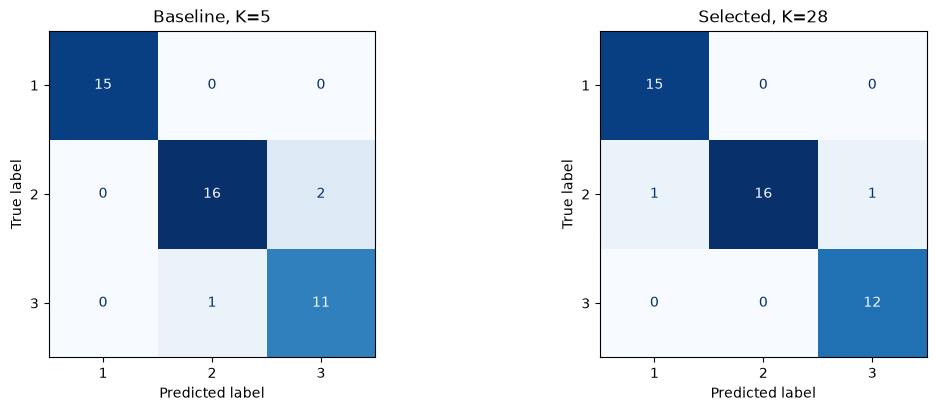

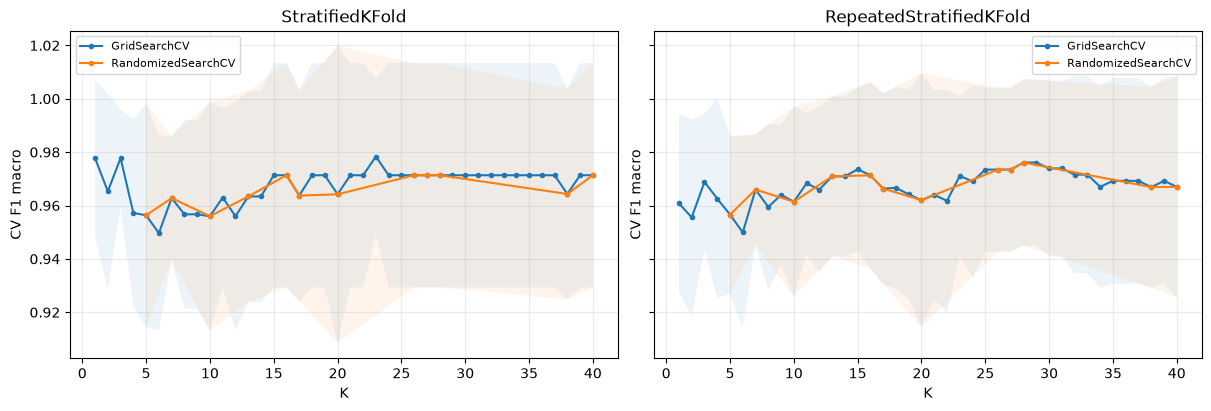

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, (label, model) in zip(axes, [("Baseline, K=5", baseline),
                                   (f"Selected, K={int(winner['K'])}", best_model)]):
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test),
        display_labels=[1, 2, 3], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(label)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, constrained_layout=True)
for ax, strategy_name in zip(axes, strategies):
    for method in ("GridSearchCV", "RandomizedSearchCV"):
        result = searches[f"{method} / {strategy_name}"].cv_results_
        ks = np.array(result["param_knn__n_neighbors"], dtype=int)
        order = np.argsort(ks)
        means = np.asarray(result["mean_test_score"])[order]
        stds = np.asarray(result["std_test_score"])[order]
        ax.plot(ks[order], means, "o-", markersize=3, label=method)
        ax.fill_between(ks[order], means-stds, means+stds, alpha=0.08)
    ax.set(title=strategy_name, xlabel="K", ylabel="CV F1 macro")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
plt.show()

## Вывод
По повторной кросс-валидации оба метода поиска выбрали K=28 (CV F1 macro=0,9761).
На тесте accuracy выросла с 0,9333 до 0,9556, F1 macro — с 0,9314 до 0,9563;
число ошибок сократилось с 3 до 2 на 45 объектах. Подбор K улучшил результат
на данном разбиении. Модель K=23 получила 1,0000 на тесте, но итоговый выбор
не меняем по тестовым метрикам. Размер теста мал, поэтому устойчивое
превосходство на новых данных из этого эксперимента не следует.